# Practical Session — ResNet, Image Classification and Transfer Learning

## Context and objectives

Modern deep learning workflows increasingly rely on pretrained models and AI-assisted programming tools. However, being able to generate or execute code is not sufficient: engineers must understand the underlying mechanisms, assess implementation choices, and identify potential limitations.

In this practical session, you will work with code generated by an AI assistant to explore image classification using convolutional neural networks and the Hugging Face ecosystem. Your task is not simply to run the code, but to **read it critically, understand its logic, and connect its implementation to the theoretical concepts studied in class**.

The session is organized into two parts.

### Part 1 — Using a pretrained ResNet model

You will first discover how to use Hugging Face to load a pretrained ResNet model and apply it to an image classification task. You will investigate the main components of the inference pipeline, including image preprocessing, model inputs and outputs, class predictions...

You will also examine the architecture of ResNet by inspecting the intermediate representations produced by its different stages. This will help you understand how spatial resolution and the number of feature channels evolve throughout a convolutional neural network.

### Part 2 — Transfer learning for a new classification task

You will then adapt a pretrained ResNet model to a new image classification task. Starting from representations learned on a large dataset, you will investigate how a model can be reused and fine-tuned for a different prediction problem.

You will examine the modifications required to the classification head, the role of the training and validation datasets, the loss function, and the optimization procedure. You will also analyze the impact of different transfer learning strategies, such as training only the classification head or fine-tuning some or all of the network parameters.

## Expected outcomes

By the end of this session, you should be able to:

- Use Hugging Face to load, preprocess inputs for, and run inference with a pretrained model.
- Explain the principles of transfer learning and implement a basic fine-tuning procedure.
- Improve your skills to critically assess AI-generated code, including its assumptions, correctness, and potential limitations.

**Throughout the session, you are expected to justify the main implementation choices and explain what the code actually does, rather than merely demonstrating that it executes successfully.**

## Part 1 — Using a pretrained ResNet model

In [1]:
!pip install -q transformers datasets scikit-learn matplotlib pandas

In [2]:
import random, time, io
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)
if device.type == "cpu":
    print("⚠️  No GPU detected: Some parts will be slow. Reduce epochs or use a GPU runtime.")

device: cuda | torch 2.11.0+cu130


The Hugging Face Hub hosts pretrained checkpoints with their model card (training data, input size, license, intended use).

The high-level pipeline API hides everything: preprocessing → forward pass → postprocessing.

Before running: open the model card of [`microsoft/resnet-50`](https://huggingface.co/microsoft/resnet-50). Which dataset was it trained on? What input resolution does it expect?

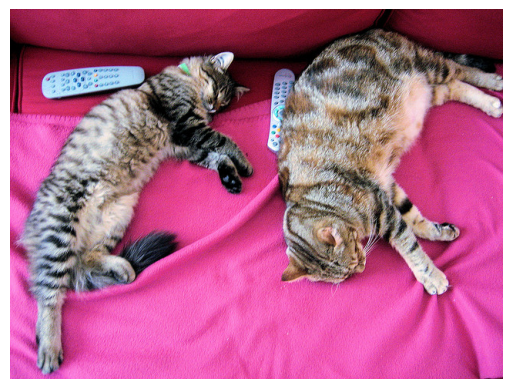

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

tiger cat                                0.941
tabby, tabby cat                         0.035
remote control, remote                   0.002
Egyptian cat                             0.001
jinrikisha, ricksha, rickshaw            0.001


In [3]:
import requests
from transformers import pipeline

def load_image_from_url(url):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

try:
    img = load_image_from_url("http://images.cocodataset.org/val2017/000000039769.jpg")
except Exception as e:
    print("URL failed, falling back to the cats-image dataset:", e)
    from datasets import load_dataset
    img = load_dataset("huggingface/cats-image", split="test")[0]["image"].convert("RGB")

plt.imshow(img); plt.axis("off"); plt.show()

classifier = pipeline("image-classification", model="microsoft/resnet-50",
                      device=0 if device.type == "cuda" else -1)
for p in classifier(img, top_k=5):
    print(f"{p['label']:<40s} {p['score']:.3f}")

**Exercise 1.1**

1. Gather **3 images of your own** (upload files in Colab or use `load_image_from_url`): at least one *easy* (a clear dog/car/…), one *ambiguous*, one with **no ImageNet class at all** (a face, a diagram, a screenshot…).
2. For each of the three models below, build a `pipeline`, measure the inference time, and print the top-3 predictions per image.

Failed to load no_imagenet_class (diagram), fallback to a placeholder: 404 Client Error: Not Found for url: https://upload.wikimedia.org/wikipedia/commons/e/e0/Placeholder_LCa.png


README.md:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

cats_image.jpeg:   0%|          | 0.00/173k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/1 [00:00<?, ? examples/s]

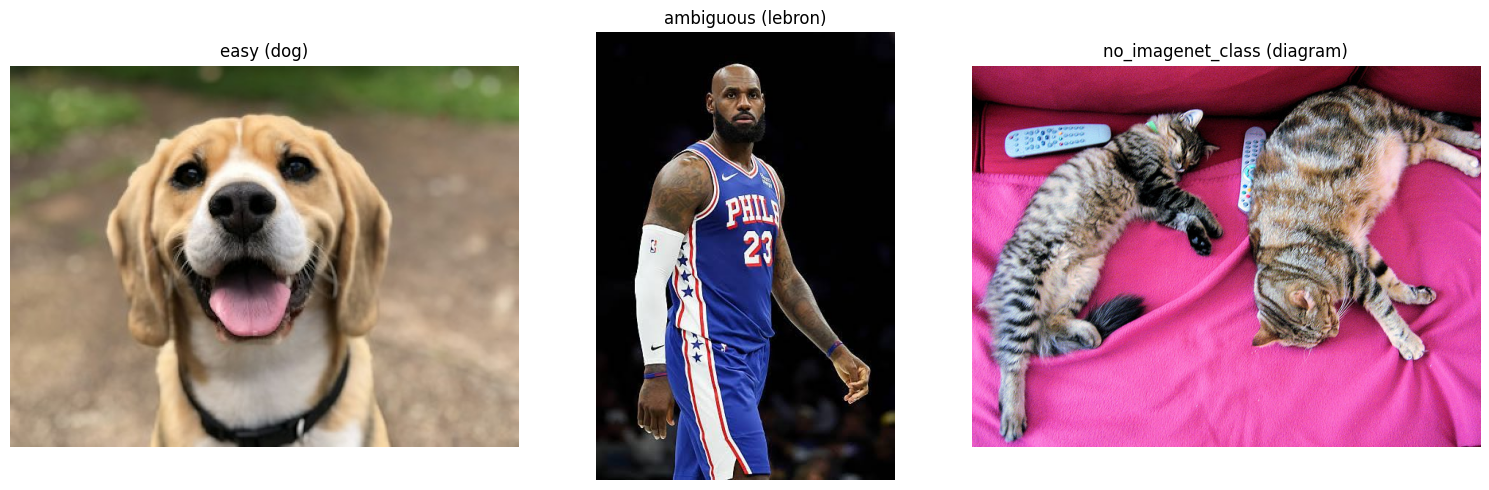

Loading model: microsoft/resnet-50


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]


[Image: easy (dog)] | Inference Time: 46.29 ms
  - beagle                                   (Confidence: 0.9206)
  - English foxhound                         (Confidence: 0.0336)
  - Labrador retriever                       (Confidence: 0.0037)

[Image: ambiguous (lebron)] | Inference Time: 46.86 ms
  - basketball                               (Confidence: 0.9987)
  - maillot                                  (Confidence: 0.0003)
  - parallel bars, bars                      (Confidence: 0.0001)

[Image: no_imagenet_class (diagram)] | Inference Time: 31.63 ms
  - tiger cat                                (Confidence: 0.9409)
  - tabby, tabby cat                         (Confidence: 0.0349)
  - remote control, remote                   (Confidence: 0.0017)
Loading model: google/vit-base-patch16-224


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

...

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]


[Image: easy (dog)] | Inference Time: 34.51 ms
  - beagle                                   (Confidence: 0.9384)
  - English foxhound                         (Confidence: 0.0484)
  - Walker hound, Walker foxhound            (Confidence: 0.0070)

[Image: ambiguous (lebron)] | Inference Time: 30.23 ms
  - basketball                               (Confidence: 0.9891)
  - maillot                                  (Confidence: 0.0087)
  - soccer ball                              (Confidence: 0.0002)


model.safetensors: reconstructing file:   0%|          |  0.00B /  349MB            

model.safetensors: downloading bytes:           |  0.00B            


[Image: no_imagenet_class (diagram)] | Inference Time: 72.69 ms
  - tabby, tabby cat                         (Confidence: 0.6132)
  - Egyptian cat                             (Confidence: 0.2753)
  - tiger cat                                (Confidence: 0.0762)


In [4]:
import time
import torch
import matplotlib.pyplot as plt
from transformers import pipeline

# 1. Sélectionner et charger 3 images différentes
urls = {
    "easy (dog)": "https://images.unsplash.com/photo-1543466835-00a7907e9de1?auto=format&fit=crop&q=80&w=400",
    "ambiguous (lebron)": "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQ6rjZ3REJpafAbOiEQ7cXFEcpj1UYEP9Hq6PJjbLGOmfooY658Qmq1HRw&s=10",
    "no_imagenet_class (diagram)": "https://upload.wikimedia.org/wikipedia/commons/e/e0/Placeholder_LCa.png"
}

images = {}
for name, url in urls.items():
    try:
        images[name] = load_image_from_url(url)
    except Exception as e:
        print(f"Failed to load {name}, fallback to a placeholder:", e)
        from datasets import load_dataset
        images[name] = load_dataset("huggingface/cats-image", split="test")[0]["image"].convert("RGB")

# Visualisation des images chargées
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 2. Définition des 3 modèles à tester
model_names = [
    "microsoft/resnet-50",
    "google/vit-base-patch16-224",
    "facebook/deit-base-distilled-patch16-224"
]

# Évaluation des modèles
device_idx = 0 if torch.cuda.is_available() else -1

for model_name in model_names:
    print("=" * 80)
    print(f"Loading model: {model_name}")
    print("=" * 80)

    # Initialisation du pipeline d'inférence
    classifier = pipeline("image-classification", model=model_name, device=device_idx)

    for img_type, img in images.items():
        # Mesure du temps d'inférence
        start_time = time.time()
        predictions = classifier(img, top_k=3)
        end_time = time.time()

        elapsed_time = (end_time - start_time) * 1000  # conversion en millisecondes

        print(f"\n[Image: {img_type}] | Inference Time: {elapsed_time:.2f} ms")
        for p in predictions:
            print(f"  - {p['label']:<40s} (Confidence: {p['score']:.4f})")

**Under the hood**

`pipeline` is convenient, but for research and fine-tuning you need the two building blocks:

- `AutoImageProcessor`: resize / crop / rescale / normalise → `pixel_values`
- `AutoModelForImageClassification`: backbone + classification head → **logits** (not probabilities)

In [5]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

ckpt = "microsoft/resnet-50"
processor = AutoImageProcessor.from_pretrained(ckpt)
model = AutoModelForImageClassification.from_pretrained(ckpt).to(device).eval()

print(processor)
print("number of classes:", len(model.config.id2label))

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ConvNextImageProcessor {
  "crop_pct": 0.875,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "ConvNextImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}

number of classes: 1000


In [6]:
inputs = processor(images=img, return_tensors="pt").to(device)
print("pixel_values:", tuple(inputs["pixel_values"].shape), inputs["pixel_values"].dtype)

with torch.no_grad():
    out = model(**inputs)
logits = out.logits
probs = logits.softmax(-1)[0]
top = probs.topk(5)
for p, i in zip(top.values, top.indices):
    print(f"{model.config.id2label[i.item()]:<40s} {p.item():.3f}")

pixel_values: (1, 3, 224, 224) torch.float32
tiger cat                                0.941
tabby, tabby cat                         0.035
remote control, remote                   0.002
Egyptian cat                             0.001
jinrikisha, ricksha, rickshaw            0.001


Have a look to the model structure

In [7]:
model

ResNetForImageClassification(
  (resnet): ResNetModel(
    (embedder): ResNetEmbeddings(
      (embedder): ResNetConvLayer(
        (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (activation): ReLU()
      )
      (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (encoder): ResNetEncoder(
      (stages): ModuleList(
        (0): ResNetStage(
          (layers): Sequential(
            (0): ResNetBottleNeckLayer(
              (shortcut): ResNetShortCut(
                (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (normalization): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              )
              (layer): Sequential(
                (0): ResNetConvLayer(
                  (convolution): Conv2d(64

Let's look at the feature hierarchy.
With output_hidden_states=True, a transformers ResNet returns the output of the embedder (stem) and of each of the 4 stages.

In [8]:
with torch.no_grad():
    out = model(**inputs, output_hidden_states=True)
for i, h in enumerate(out.hidden_states):
    print(f"hidden_states[{i}]: {tuple(h.shape)}")

hidden_states[0]: (1, 64, 56, 56)
hidden_states[1]: (1, 256, 56, 56)
hidden_states[2]: (1, 512, 28, 28)
hidden_states[3]: (1, 1024, 14, 14)
hidden_states[4]: (1, 2048, 7, 7)


In [9]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

blocks = {"embedder": model.resnet.embedder,
          **{f"stage{i}": s for i, s in enumerate(model.resnet.encoder.stages)},
          "classifier": model.classifier}
total = n_params(model)
print(f"total: {total/1e6:.2f} M parameters")
for k, m in blocks.items():
    print(f"{k:<11s} {n_params(m)/1e6:6.2f} M  ({100*n_params(m)/total:4.1f} %)")

total: 25.56 M parameters
embedder      0.01 M  ( 0.0 %)
stage0        0.22 M  ( 0.8 %)
stage1        1.22 M  ( 4.8 %)
stage2        7.10 M  (27.8 %)
stage3       14.96 M  (58.6 %)
classifier    2.05 M  ( 8.0 %)


idx 0 | res 56x56 | channels   64 | stride 4
idx 1 | res 56x56 | channels  256 | stride 4
idx 2 | res 28x28 | channels  512 | stride 8
idx 3 | res 14x14 | channels 1024 | stride 16
idx 4 | res  7x7  | channels 2048 | stride 32


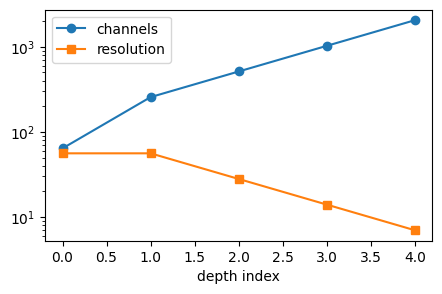

In [10]:
H = inputs["pixel_values"].shape[-1]
rows = []
for i, h in enumerate(out.hidden_states):
    rows.append((i, h.shape[-1], h.shape[1], H // h.shape[-1]))
for r in rows: print("idx %d | res %2dx%-2d | channels %4d | stride %d" % (r[0], r[1], r[1], r[2], r[3]))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([r[0] for r in rows], [r[2] for r in rows], "o-", label="channels")
ax.plot([r[0] for r in rows], [r[1] for r in rows], "s-", label="resolution")
ax.set_yscale("log"); ax.set_xlabel("depth index"); ax.legend(); plt.show()

Expected: the (Embedder) stem divides resolution by 4; each stage then divides it by 2 (except the first) while channels grow ×2 (stage widths 256 → 512 → 1024 → 2048 for ResNet-50).

Early layers detect local, generic patterns (edges, textures); deep layers respond to class-specific parts. Let's check on a real image.

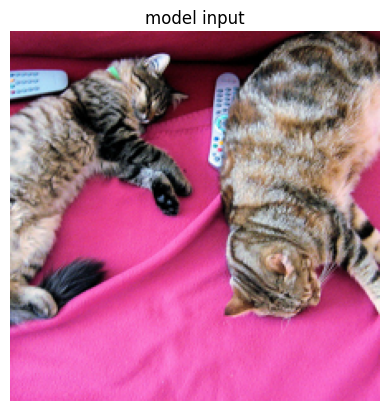

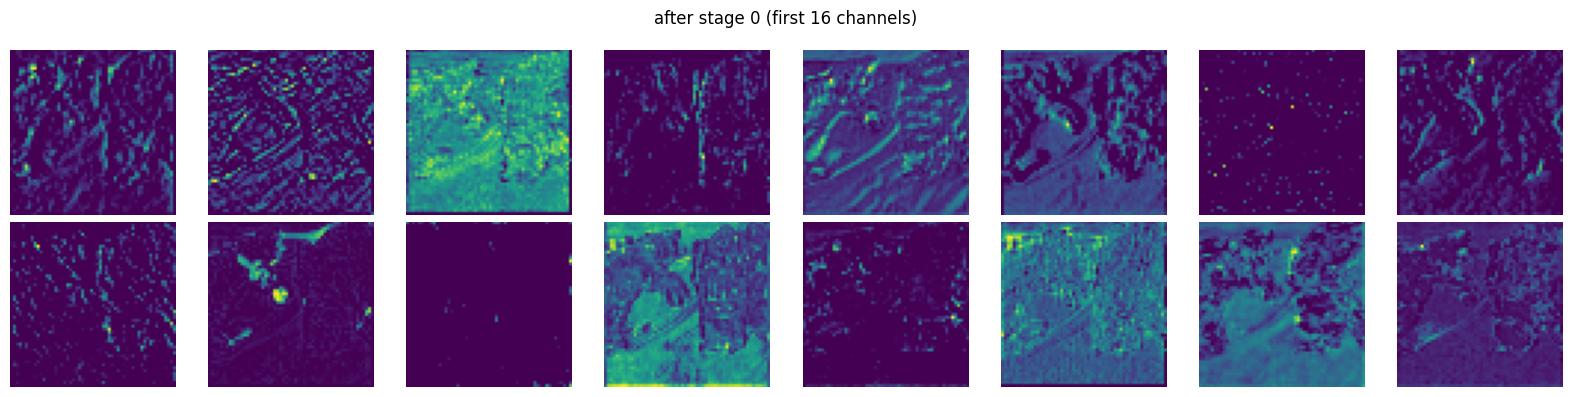

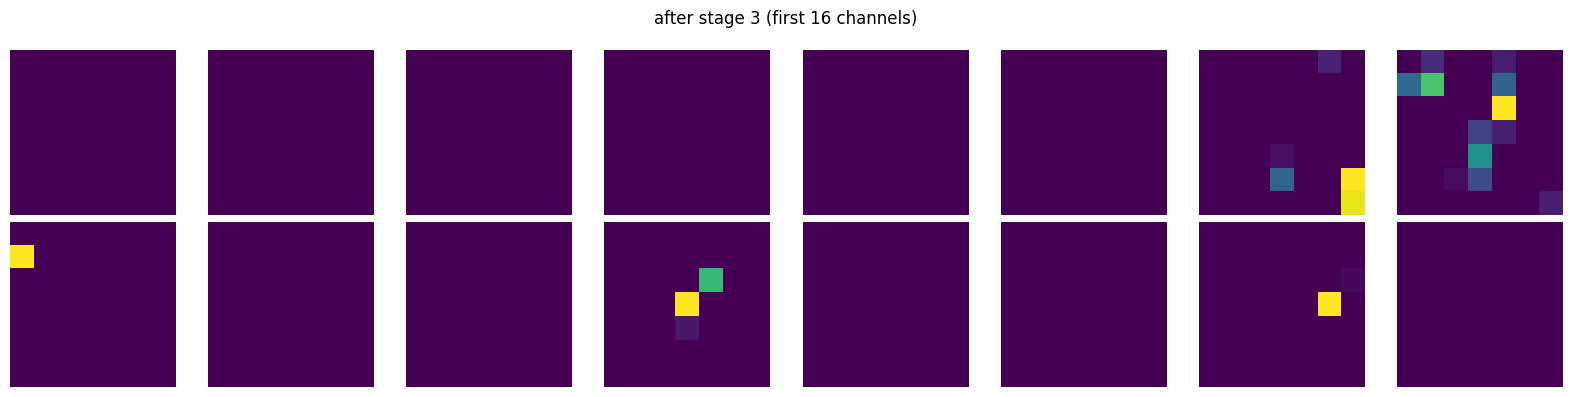

In [11]:
def denorm(pixel_values, processor):
    mean = torch.tensor(processor.image_mean).view(1, 3, 1, 1)
    std = torch.tensor(processor.image_std).view(1, 3, 1, 1)
    return (pixel_values.detach().cpu() * std + mean).clamp(0, 1)[0].permute(1, 2, 0).numpy()

def show_feature_maps(fmap, n=16, title=""):
    fmap = fmap[0].detach().cpu()
    cols = 8
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for k in range(n): axes[k].imshow(fmap[k], cmap="viridis")
    fig.suptitle(title); plt.tight_layout(); plt.show()

x_img = denorm(inputs["pixel_values"], processor)
plt.imshow(x_img); plt.axis("off"); plt.title("model input"); plt.show()
show_feature_maps(out.hidden_states[1], title="after stage 0 (first 16 channels)")
show_feature_maps(out.hidden_states[4], title="after stage 3 (first 16 channels)")

## Part 2 — Transfer learning for a new classification task

**Task:** diagnose bean-leaf diseases from photos — [`AI-Lab-Makerere/beans`](https://huggingface.co/datasets/AI-Lab-Makerere/beans) (3 classes: *angular leaf spot*, *bean rust*, *healthy*; ~1k training images).

We will compare three regimes with the **same backbone** (`microsoft/resnet-18`):

| Regime | What is trained | Intuition |
|---|---|---|
| **Linear probing** | only the new linear head | "are ImageNet features already good enough?" |
| **Full fine-tuning** | everything, small LR | "adapt all features to the new domain" |
| **From scratch** | everything, random init | "what did pretraining actually buy us?" |

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
['angular_leaf_spot', 'bean_rust', 'healthy']


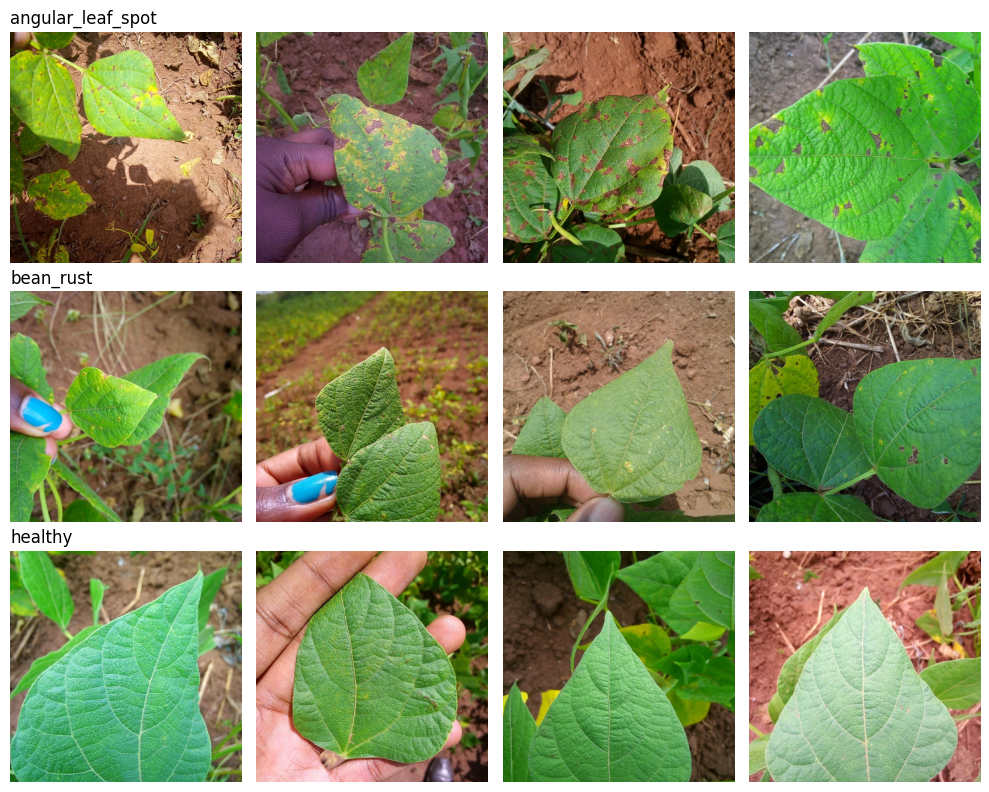

In [12]:
from datasets import load_dataset

ds = load_dataset("AI-Lab-Makerere/beans")
print(ds)
class_names = ds["train"].features["labels"].names
print(class_names)

labels_train = ds["train"]["labels"]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for c, name in enumerate(class_names):
    idxs = [i for i, l in enumerate(labels_train) if l == c][:4]
    for j, i in enumerate(idxs):
        axes[c, j].imshow(ds["train"][i]["image"]); axes[c, j].axis("off")
    axes[c, 0].set_title(name, loc="left")
plt.tight_layout(); plt.show()

In [13]:
import copy
from transformers import AutoConfig, AutoModelForImageClassification

# Définition de la variable CKPT manquante
CKPT = "microsoft/resnet-18"
num_classes = len(class_names) # 3 classes

# =====================================================================
# 1. LINEAR PROBING MODEL
# =====================================================================
print("Initializing Linear Probing Model...")
model_lp = AutoModelForImageClassification.from_pretrained(CKPT)

# Étape A: Bloquer tous les paramètres du backbone
for param in model_lp.parameters():
    param.requires_grad = False

# Étape B: Remplacer la tête de classification (qui sera donc la seule entraînable)
in_features = model_lp.classifier[1].in_features
model_lp.classifier = nn.Sequential(
    nn.Flatten(start_dim=1, end_dim=-1),
    nn.Linear(in_features, num_classes)
)
model_lp = model_lp.to(device)

# =====================================================================
# 2. FULL FINE-TUNING MODEL
# =====================================================================
print("Initializing Full Fine-Tuning Model...")
model_ft = AutoModelForImageClassification.from_pretrained(CKPT)

# Remplacer la tête de classification (tous les paramètres requièrent déjà requires_grad=True par défaut)
in_features = model_ft.classifier[1].in_features
model_ft.classifier = nn.Sequential(
    nn.Flatten(start_dim=1, end_dim=-1),
    nn.Linear(in_features, num_classes)
)
model_ft = model_ft.to(device)

# =====================================================================
# 3. FROM SCRATCH MODEL
# =====================================================================
print("Initializing From Scratch Model (Random initialization)...")
# Charger uniquement la configuration de l'architecture sans charger les poids pré-entraînés
config = AutoConfig.from_pretrained(CKPT, num_labels=num_classes)
model_scratch = AutoModelForImageClassification.from_config(config)
model_scratch = model_scratch.to(device)

print("\nModels initialized successfully!")

Initializing Linear Probing Model...


config.json:   0%|          | 0.00/69.5k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/122 [00:00<?, ?it/s]

Initializing Full Fine-Tuning Model...


Loading weights:   0%|          | 0/122 [00:00<?, ?it/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


Initializing From Scratch Model (Random initialization)...

Models initialized successfully!


### Data pipeline

Two rules to keep in mind when using a pretrained backbone:
1. Use the **same normalisation** as pretraining (`processor.image_mean / image_std`).
2. Data augmentation only on the **training** split.

In [14]:
from torchvision import transforms as T
from torch.utils.data import DataLoader

CKPT = "microsoft/resnet-18"
BATCH = 32

def build_tf(processor, train):
    norm = T.Normalize(processor.image_mean, processor.image_std)
    if train:
        return T.Compose([T.RandomResizedCrop(224, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                          T.ToTensor(), norm])
    return T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm])

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["labels"] for b in batch])}

def make_loader(split, processor, train):
    tf = build_tf(processor, train)
    def transform(batch):
        return {"pixel_values": [tf(im.convert("RGB")) for im in batch["image"]],
                "labels": batch["labels"]}
    return DataLoader(ds[split].with_transform(transform), batch_size=BATCH,
                      shuffle=train, num_workers=2, collate_fn=collate)

processor_r18 = AutoImageProcessor.from_pretrained(CKPT)
train_loader = make_loader("train", processor_r18, train=True)
val_loader = make_loader("validation", processor_r18, train=False)
test_loader = make_loader("test", processor_r18, train=False)
print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

1034 133 128


In [18]:
def train_model(model, train_loader, val_loader, epochs=5, lr=1e-3):
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            optimizer.zero_grad()
            outputs = model(pixel_values)
            loss = criterion(outputs.logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)

        # Validation phase
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch in val_loader:
                pixel_values = batch["pixel_values"].to(device)
                labels = batch["labels"].to(device)
                outputs = model(pixel_values)
                preds = outputs.logits.argmax(-1)
                correct += (preds == labels).sum().item()
                total += len(labels)

        epoch_loss = total_loss / len(train_loader.dataset)
        val_acc = correct / total
        history["train_loss"].append(epoch_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_loss:.4f} | Val Acc: {val_acc:.4f}")

    return history

def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in test_loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)
            outputs = model(pixel_values)
            preds = outputs.logits.argmax(-1)
            correct += (preds == labels).sum().item()
            total += len(labels)
    return correct / total

In [17]:
print("=== Training Linear Probing ===")
# Linear probing typically works well with a slightly higher learning rate as only the head is updated
epoch_history_lp = train_model(model_lp, train_loader, val_loader, epochs=5, lr=1e-3)
acc_lp = evaluate_model(model_lp, test_loader)

print("\n=== Training Full Fine-Tuning ===")
# Full fine-tuning requires a smaller learning rate to preserve pretrained representations
epoch_history_ft = train_model(model_ft, train_loader, val_loader, epochs=5, lr=1e-4)
acc_ft = evaluate_model(model_ft, test_loader)

print("\n=== Training From Scratch ===")
# Training from scratch typically needs a standard learning rate but lacks prior knowledge
epoch_history_scratch = train_model(model_scratch, train_loader, val_loader, epochs=5, lr=1e-4)
acc_scratch = evaluate_model(model_scratch, test_loader)

print(f"\nTest Accuracy Results:\nLinear Probing: {acc_lp:.4f}\nFull Fine-Tuning: {acc_ft:.4f}\nFrom Scratch: {acc_scratch:.4f}")

=== Training Linear Probing ===
Epoch 1/5 | Train Loss: 0.8929 | Val Acc: 0.7970
Epoch 2/5 | Train Loss: 0.6206 | Val Acc: 0.8421
Epoch 3/5 | Train Loss: 0.5212 | Val Acc: 0.9173
Epoch 4/5 | Train Loss: 0.4733 | Val Acc: 0.8947
Epoch 5/5 | Train Loss: 0.4215 | Val Acc: 0.9023

=== Training Full Fine-Tuning ===
Epoch 1/5 | Train Loss: 0.4189 | Val Acc: 0.9474
Epoch 2/5 | Train Loss: 0.1126 | Val Acc: 0.9624
Epoch 3/5 | Train Loss: 0.0851 | Val Acc: 0.9774
Epoch 4/5 | Train Loss: 0.0433 | Val Acc: 0.9925
Epoch 5/5 | Train Loss: 0.0381 | Val Acc: 0.9850

=== Training From Scratch ===
Epoch 1/5 | Train Loss: 0.8001 | Val Acc: 0.5865
Epoch 2/5 | Train Loss: 0.6753 | Val Acc: 0.7293
Epoch 3/5 | Train Loss: 0.5908 | Val Acc: 0.7519
Epoch 4/5 | Train Loss: 0.5363 | Val Acc: 0.7820
Epoch 5/5 | Train Loss: 0.5051 | Val Acc: 0.7895

Test Accuracy Results:
Linear Probing: 0.8672
Full Fine-Tuning: 0.9688
From Scratch: 0.8203


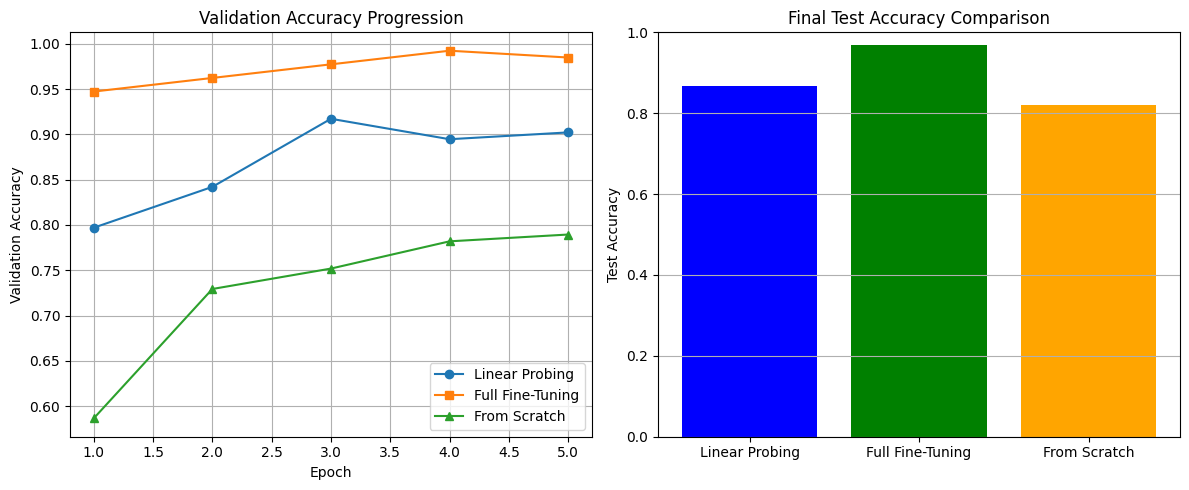

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, 6)
plt.figure(figsize=(12, 5))

# Plot validation accuracies
plt.subplot(1, 2, 1)
plt.plot(epochs, epoch_history_lp["val_acc"], 'o-', label='Linear Probing')
plt.plot(epochs, epoch_history_ft["val_acc"], 's-', label='Full Fine-Tuning')
plt.plot(epochs, epoch_history_scratch["val_acc"], '^-', label='From Scratch')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Progression')
plt.grid(True)
plt.legend()

# Plot final test comparison
plt.subplot(1, 2, 2)
methods = ['Linear Probing', 'Full Fine-Tuning', 'From Scratch']
accuracies = [acc_lp, acc_ft, acc_scratch]
plt.bar(methods, accuracies, color=['blue', 'green', 'orange'])
plt.ylabel('Test Accuracy')
plt.title('Final Test Accuracy Comparison')
plt.ylim(0, 1.0)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

Exercise:

1.   Implement the code to compare the different regimes with regard to accuracy.
2.   Evaluate how the best model degrades under distribution shift (apply Gaussian noise and Gaussian blur to the test set and track accuracy, e.g. functions defined below).





In [15]:
def gaussian_noise(s):
    return lambda x: (x + s * torch.randn_like(x)).clamp(0, 1)

def gaussian_blur(s):
    if s == 0: return lambda x: x
    k = 2 * int(np.ceil(3 * s)) + 1
    return lambda x: T.functional.gaussian_blur(x, kernel_size=k, sigma=s)